# 08 · How common is low building coverage among claims?
**Venkat Repaka and Ritik Gaire · NFIP flood claims**

**Question:** how common is low building coverage among claims?

We compare building coverage with the reported cost of rebuilding. Because NFIP cover is capped, we separate buildings that could buy more cover from buildings already at the cap.

**Learning bridge:** payment and severity models used policy coverage as a strong input. We now ask what that input means relative to rebuilding cost. We move from a ratio to a cap-aware definition, then check whether the definition changes the conclusion.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from project_utils import *
pd.set_option('display.max_columns', 20)
pd.set_option('display.float_format', lambda x: f'{x:,.3f}')
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
df=load_joined()

### Step 1 · Define the ratio and show its distribution
Coverage divided by replacement cost makes unlike building sizes easier to compare, but only when the two fields refer to compatible values.

Usable claims: 218,852 of 277,033


,claims,median_itv,share_below_80,share_above_2
occupancy_name,,,,
2-4 units,9292,0.661,0.658,0.006
5+ units,3985,0.311,0.898,0.004
condo building,13520,0.973,0.282,0.017
mobile home,5068,0.721,0.558,0.042
non-res. mobile,63,0.963,0.429,0.063
non-residential,15173,0.373,0.806,0.021
single family,169719,0.756,0.540,0.009
unit in building,2032,0.624,0.640,0.035


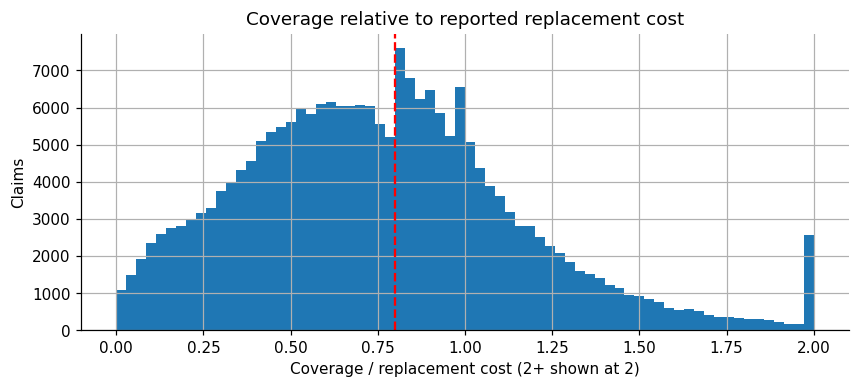

In [2]:
d=df[(df.buildingReplacementCost>0)&(df.totalBuildingInsuranceCoverage>0)].copy()
d['itv']=d.totalBuildingInsuranceCoverage/d.buildingReplacementCost
print(f'Usable claims: {len(d):,} of {len(df):,}')
display(d.groupby('occupancy_name').agg(claims=('id','size'),median_itv=('itv','median'),
    share_below_80=('itv',lambda s:s.lt(.8).mean()),share_above_2=('itv',lambda s:s.gt(2).mean())).round(3))
fig,ax=plt.subplots(figsize=(9,3.5))
d.itv.clip(upper=2).hist(bins=70,ax=ax);ax.axvline(.8,color='red',ls='--')
ax.set(xlabel='Coverage / replacement cost (2+ shown at 2)',ylabel='Claims',title='Coverage relative to reported replacement cost');plt.show()

### Step 2 · Why the simple “below 80%” label is incomplete
The NFIP cap can prevent a high-cost home from reaching 80% using NFIP cover alone. We compare the threshold with the coverage amount before assigning a descriptive group.

In [3]:
preview=d[d.occupancy=='11'].copy()
print('Single-family claims below 80%:',preview.itv.lt(.8).mean())
print('Single-family claims at/above $250k:',preview.totalBuildingInsuranceCoverage.ge(249999).mean())

Single-family claims below 80%: 0.5399041945804536
Single-family claims at/above $250k: 0.6460914806238547


## 1. Define coverage groups carefully
We use 80% as an analysis benchmark. Being below it does not by itself prove that an owner made a poor choice or that a payment rule was violated.

For single-family homes we distinguish:
- coverage at least 80% of replacement cost;
- coverage below 80%, but at or above the $250,000 NFIP building benchmark;
- coverage below 80% and below that benchmark.

The last group has **low coverage below the cap**. We cannot call it voluntary underinsurance: affordability, advice, policy rules and other insurance are not observed. We restrict this cap comparison to single-family homes to avoid uncertain condo and multi-unit limits.

### Step 3 · Separate adequacy from the cap
We keep the main cap comparison to single-family homes.

In [4]:
homes=d[d.occupancy=='11'].copy()
homes['coverage_group']=np.select([homes.itv.ge(.8),homes.totalBuildingInsuranceCoverage.ge(249999)],
    ['at least 80%','below 80%, at cap'],default='below 80%, below cap')
summary=homes.groupby('coverage_group').agg(claims=('id','size'),median_replacement=('buildingReplacementCost','median'),
    median_coverage=('totalBuildingInsuranceCoverage','median'),median_itv=('itv','median'))
summary['share']=summary.claims/len(homes)
display(summary.round(3));save_table(summary,'08_single_family_coverage')

,claims,median_replacement,median_coverage,median_itv,share
coverage_group,,,,,
at least 80%,78087,"215,660.000","250,000.000",1.015,0.460
"below 80%, at cap",61491,"454,751.000","250,000.000",0.550,0.362
"below 80%, below cap",30141,"236,331.000","104,000.000",0.486,0.178


### Step 4 · Ask which observed groups have low cover
This is a descriptive association with rebuilding cost, not evidence of a voluntary decision.

In [5]:
homes['low_below_cap']=homes.coverage_group.eq('below 80%, below cap').astype(int)
homes['value_group']=pd.qcut(homes.buildingReplacementCost,4,labels=['lowest cost','second','third','highest cost'])
display(homes.groupby('value_group',observed=True).agg(claims=('id','size'),low_below_cap=('low_below_cap','mean')).round(3))

,claims,low_below_cap
value_group,,
lowest cost,42430,0.247
second,42430,0.212
third,42429,0.183
highest cost,42430,0.068


## 2. Sensitivity to the definition
The 80% cutoff is a choice. We also show 70%, 90% and 100%. Values far above 1 can reflect inconsistent valuation or different reporting units; they are not proof of extra financial protection. We compare results after excluding ratios above 2 as a sensitivity check.

In [6]:
rows=[]
for sample,g in [('all usable',homes),('ITV at most 2',homes[homes.itv<=2])]:
    for cutoff in [.7,.8,.9,1.0]:
        rows.append({'sample':sample,'adequacy cutoff':cutoff,'claims':len(g),
                     'below cutoff':g.itv.lt(cutoff).mean(),
                     'below cutoff and cap':(g.itv.lt(cutoff)&g.totalBuildingInsuranceCoverage.lt(249999)).mean()})
display(pd.DataFrame(rows).set_index(['sample','adequacy cutoff']).round(3))

claims  below cutoff  below cutoff and cap
sample        adequacy cutoff                                            
all usable    0.700            169719         0.442                 0.151
              0.800            169719         0.540                 0.178
              0.900            169719         0.658                 0.229
              1.000            169719         0.753                 0.267
ITV at most 2 0.700            168263         0.446                 0.152
              0.800            168263         0.545                 0.179
              0.900            168263         0.664                 0.231
              1.000            168263         0.759                 0.269

## 3. Recorded damage above building coverage
We calculate max(damage − coverage, 0). This is damage beyond the recorded NFIP building coverage. It is not a complete measure of unpaid loss: deductibles, other insurance and differences in valuation are not included.

In [7]:
damaged=d[d.buildingDamageAmount>0].copy()
damaged['above_coverage']=(damaged.buildingDamageAmount-damaged.totalBuildingInsuranceCoverage).clip(lower=0)
cost=damaged.groupby('occupancy_name').agg(claims=('id','size'),share_above=('above_coverage',lambda s:s.gt(0).mean()),
    damage_above_coverage=('above_coverage','sum'))
display(cost.sort_values('damage_above_coverage',ascending=False).round(2))
print(f'Total recorded damage above coverage in usable claims: ${damaged.above_coverage.sum()/1e9:.3f} billion')
save_table(cost,'08_damage_above_coverage')

,claims,share_above,damage_above_coverage
occupancy_name,,,
non-residential,14476,0.120,"211,821,114.000"
single family,163551,0.040,"207,438,630.000"
condo building,12962,0.020,"71,135,197.000"
5+ units,3753,0.120,"39,916,850.000"
mobile home,4931,0.220,"19,567,301.000"
2-4 units,9014,0.050,"15,035,544.000"
unit in building,1272,0.060,"1,182,896.000"
non-res. mobile,61,0.080,"64,326.000"


Total recorded damage above coverage in usable claims: $0.566 billion


## 4. Changes over time
Storms hit different types of homes each year. A trend in claims is not the same as a trend among all insured homes. We show year summaries and avoid treating the latest rating-system field as the rating method at the loss date.

,claims,median_itv,low_below_cap,florida_share
loss_year,,,,
2020,22382,0.875,0.214,0.291
2021,29804,0.812,0.245,0.013
2022,33089,0.714,0.125,0.825
2023,13169,0.810,0.172,0.513
2024,62843,0.714,0.138,0.779
2025,8432,0.653,0.358,0.028


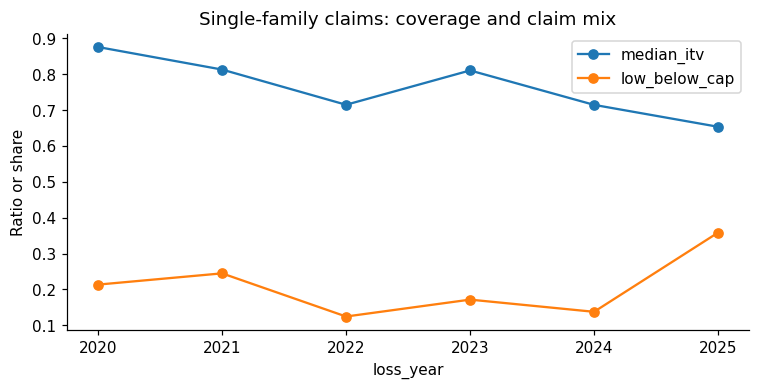

In [8]:
year=homes.groupby('loss_year').agg(claims=('id','size'),median_itv=('itv','median'),low_below_cap=('low_below_cap','mean'),
    florida_share=('state',lambda s:s.eq('FL').mean()))
display(year.round(3))
year[['median_itv','low_below_cap']].plot(marker='o',figsize=(8,3.5),title='Single-family claims: coverage and claim mix')
plt.ylabel('Ratio or share');plt.show()

## 5. Answer and limits
**Answer.** About 18% of single-family claims have coverage below 80% of the rebuilding cost *and* below the $250,000 NFIP limit. Another 36% are below 80% only because the building costs more than the $250,000 limit allows. So most "low coverage" comes from the cap, not from choosing little cover. The share of low coverage is highest for the cheapest homes.

**What we cannot say.** We do not know why people chose their cover (price, advice, other insurance). Rebuilding cost is reported after the loss and can be wrong. Homes with no claim, and uninsured homes, are not in the data. We cannot measure the effect of Risk Rating 2.0 from these summaries.

**A modelling note.** Coverage and rebuilding cost define the outcome, so using them to "predict" low coverage would only repeat the definition.

### Decision ledger
We kept the coverage ratio but refined the single 80% label with a cap-aware comparison. We varied the cutoff to expose definition sensitivity. We discarded “underinsured by choice” because motives and other insurance are absent. Notebook 09 now adds neighborhood context while keeping those limits.

### Result in plain English

Among usable single-family claims, **17.8%** have coverage below 80% of reported replacement cost and below the $250,000 benchmark. This describes low recorded NFIP coverage. It does not show whether affordability, advice, other cover or an owner preference explains the amount. The reported damage above coverage is also narrower than total unpaid flood loss.